# 02 · Clustering K-Means — Patrón de comportamiento

**Objetivo:** encontrar grupos de estudiantes con hábitos de estudio parecidos. Solo se usan **hábitos** (horas, asistencia, actividades, ejercicios, comprensión) y no las notas, para que el cluster describa *cómo estudia* el estudiante y no *qué nota sacó*. El cluster se agregará después como feature en el modelo híbrido.

Los datos son sintéticos y el K-Means se ajusta **solo con train**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from features import RAIZ, HABITOS, OBJETIVO, SEED
from modelo import K_CLUSTERS, pipeline_kmeans, nombres_clusters

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
df = pd.read_csv(RAIZ / "data/processed/registros_limpios.csv")
train, test = df[df.particion == "train"], df[df.particion == "test"]
print(train.shape, test.shape)
train[HABITOS].describe().round(2)

(4804, 23) (1196, 23)


,horas_estudio_semana,asistencia_pct,actividades_completadas_pct,ejercicios_correctos_pct,comprension_tema
count,4671.00,4804.00,4804.00,4669.00,4667.00
mean,6.96,86.37,76.37,54.15,2.87
std,3.31,8.97,17.16,17.18,1.04
min,0.00,46.60,9.30,0.00,1.00
25%,4.70,80.30,64.70,42.50,2.00
50%,7.00,86.80,77.20,53.90,3.00
75%,9.10,93.00,90.60,66.20,4.00
max,19.40,100.00,100.00,100.00,5.00


## 1. Escalado
K-Means usa distancias euclidianas. Sin escalar, `asistencia_pct` (0-100) pesaría mucho más que `comprension_tema` (1-5). Por eso se imputa con la mediana y se estandariza (z-score), ajustando ambos pasos solo con train.

In [2]:
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(train[HABITOS])
X = prep.transform(train[HABITOS])
print("media ≈ 0:", X.mean(0).round(3), "| desv ≈ 1:", X.std(0).round(3))

media ≈ 0: [ 0.  0.  0. -0.  0.] | desv ≈ 1: [1. 1. 1. 1. 1.]


## 2. Elección de k: método del codo y coeficiente de silueta

k,2,3,4,5,6,7,8,9,10
inercia,18361.0707,15307.3036,13722.7270,12747.5410,11845.9027,11130.0113,10567.1526,10114.7174,9745.2964
silueta,0.2119,0.1902,0.1676,0.1618,0.1563,0.1593,0.1592,0.1542,0.1521
caida_inercia,NaN,3053.7670,1584.5766,975.1860,901.6382,715.8915,562.8587,452.4352,369.4209
cambio_caida,NaN,NaN,-1469.1904,-609.3906,-73.5478,-185.7468,-153.0328,-110.4234,-83.0143


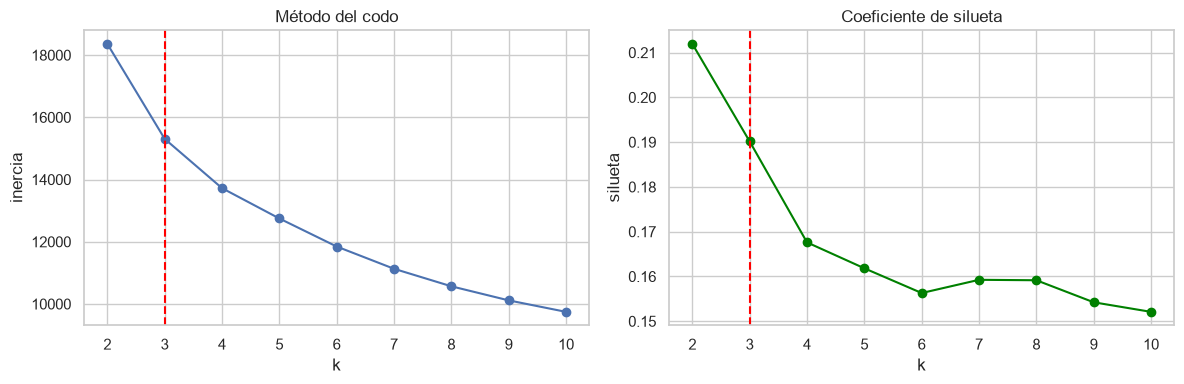

In [3]:
ks = range(2, 11)
res = []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    res.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(X, km.labels_)})
res = pd.DataFrame(res).set_index("k")
res["caida_inercia"] = -res.inercia.diff()
res["cambio_caida"] = res.caida_inercia.diff()
display(res.round(4).T)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(res.index, res.inercia, "o-"); axs[0].axvline(K_CLUSTERS, color="red", ls="--")
axs[0].set(title="Método del codo", xlabel="k", ylabel="inercia")
axs[1].plot(res.index, res.silueta, "o-", color="green"); axs[1].axvline(K_CLUSTERS, color="red", ls="--")
axs[1].set(title="Coeficiente de silueta", xlabel="k", ylabel="silueta")
plt.tight_layout(); plt.show()

In [4]:
print("k con mayor silueta:", res.silueta.idxmax())
print("k del codo (mayor reducción de la caída de inercia):", res.cambio_caida.idxmin() - 1)

k con mayor silueta: 2
k del codo (mayor reducción de la caída de inercia): 3


**Decisión: k = 3.**
- **Codo:** la caída de inercia se frena más bruscamente después de k = 3.
- **Silueta:** el valor más alto está en k = 2. Con k = 2 solo se separaría "estudia bien" de "estudia mal", y la silueta de k = 3 está cerca de ese máximo.
- **Interpretación:** k = 3 da tres perfiles con significado distinto y accionable.

**Limitación honesta:** la silueta es baja (< 0,25) para cualquier k. Los hábitos varían de forma continua y no forman grupos muy separados, así que los clusters son una *segmentación útil* de ese continuo y no grupos "naturales". Además, los datos son sintéticos.

## 3. Modelo final e interpretación de cada cluster

In [5]:
km_pipe = pipeline_kmeans(K_CLUSTERS).fit(train[HABITOS])
nombres = nombres_clusters(km_pipe)
train = train.assign(cluster=km_pipe.transform(train[HABITOS]).ravel())
test = test.assign(cluster=km_pipe.transform(test[HABITOS]).ravel())
print("Silueta k=3 (train):", round(silhouette_score(X, train.cluster), 4))

centros_z = pd.DataFrame(km_pipe[-1].km_.cluster_centers_, columns=HABITOS)
perfil = train.groupby("cluster")[HABITOS].mean()
perfil["n_registros"] = train.cluster.value_counts().sort_index()
perfil["tasa_riesgo_train"] = train.groupby("cluster")[OBJETIVO].mean()
perfil["tasa_riesgo_test"] = test.groupby("cluster")[OBJETIVO].mean()
perfil["trabaja"] = train.groupby("cluster")["trabaja"].mean()
perfil.insert(0, "nombre", perfil.index.map(nombres))
display(perfil.round(3))

Silueta k=3 (train): 0.1902


,nombre,horas_estudio_semana,asistencia_pct,actividades_completadas_pct,ejercicios_correctos_pct,comprension_tema,n_registros,tasa_riesgo_train,tasa_riesgo_test,trabaja
cluster,,,,,,,,,,
0,"esfuerzo alto, baja comprension",9.099,91.451,84.449,43.832,2.379,1607,0.242,0.237,0.211
1,pocas horas y baja constancia,4.490,80.054,61.779,48.721,2.377,1595,0.367,0.360,0.340
2,estudio constante y dominio,7.272,87.556,82.798,69.770,3.850,1602,0.021,0.036,0.287


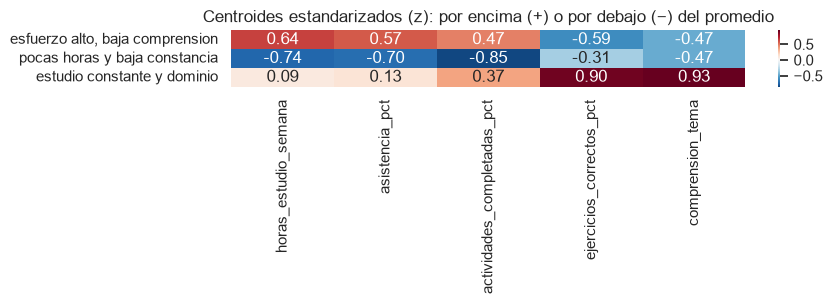

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(centros_z.set_index(centros_z.index.map(nombres)), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Centroides estandarizados (z): por encima (+) o por debajo (−) del promedio")
plt.tight_layout(); plt.show()

**Regla de nombres** (`modelo.nombrar_cluster`), según el centroide estandarizado de horas de estudio y comprensión:

| horas (z) | comprensión (z) | nombre |
|---|---|---|
| + | + | estudio constante y dominio |
| − | + | eficiente con pocas horas |
| + | − | esfuerzo alto, baja comprensión |
| − | − | pocas horas y baja constancia |

**Lectura de los perfiles** (ver la tabla de arriba):
- **Estudio constante y dominio:** buena asistencia, entrega las actividades, acierta los ejercicios y comprende el tema. Su riesgo es casi nulo.
- **Esfuerzo alto, baja comprensión:** dedica muchas horas, asiste y entrega, pero acierta pocos ejercicios y comprende poco. Necesita *cambiar la forma de estudiar* (tutoría, practicar ejercicios), no estudiar más horas.
- **Pocas horas y baja constancia:** menos horas, menos asistencia y menos actividades entregadas. Es el perfil de mayor riesgo y se relaciona con trabajar mientras estudia.

Las tasas de riesgo en test son parecidas a las de train, así que el patrón se mantiene con estudiantes que el modelo no vio.

## 4. Visualización (PCA 2D)

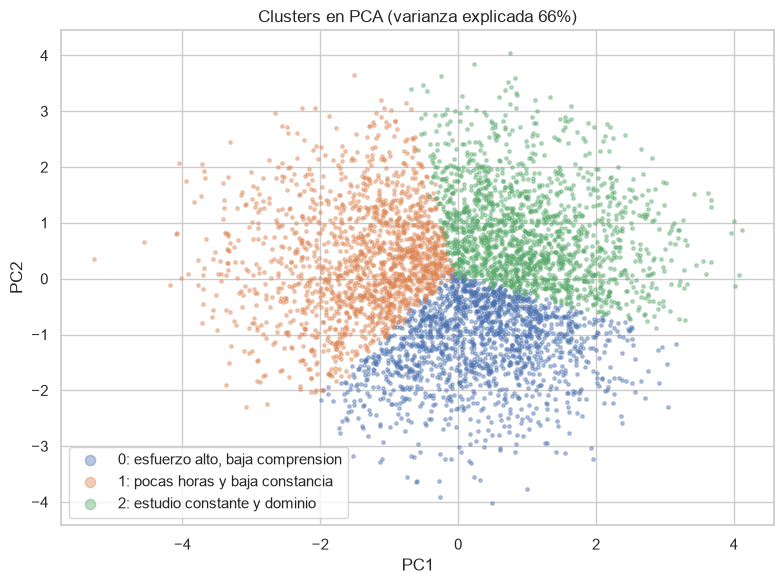

In [7]:
pca = PCA(2, random_state=SEED).fit(X)
P = pca.transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
for c, nom in nombres.items():
    m = train.cluster.values == c
    ax.scatter(P[m, 0], P[m, 1], s=6, alpha=0.4, label=f"{c}: {nom}")
ax.set(title=f"Clusters en PCA (varianza explicada {pca.explained_variance_ratio_.sum():.0%})",
       xlabel="PC1", ylabel="PC2")
ax.legend(markerscale=3); plt.tight_layout(); plt.show()

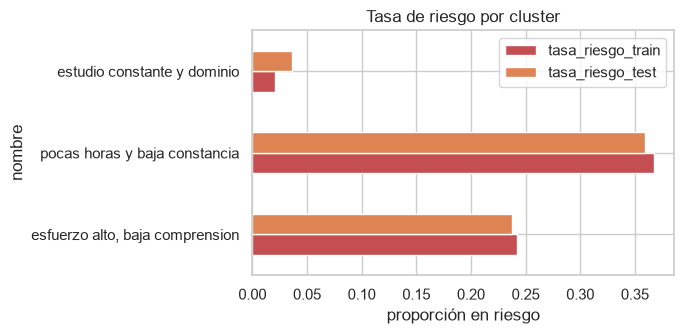

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
t = perfil.set_index("nombre")[["tasa_riesgo_train", "tasa_riesgo_test"]]
t.plot.barh(ax=ax, color=["#C44E52", "#DD8452"])
ax.set(title="Tasa de riesgo por cluster", xlabel="proporción en riesgo")
plt.tight_layout(); plt.show()